# Daily Remittance Signals in Revenue-Based Finance

This notebook examines a narrow question: **how early, and how reliably, does daily remittance behavior signal an eventual default?**

The study uses a fully synthetic portfolio of 500 advances. Parameters are chosen to be plausible for small-business revenue-based finance, but no figure here describes any actual portfolio, funder, or investment.

**Contents**
1. Simulated portfolio
2. Return behavior ahead of default
3. Collection curves
4. Predictive value of trailing return counts
5. Watch-list thresholds
6. Observations for underwriting and servicing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(2026)
GOLD, INK, GREY = "#CA9630", "#111111", "#8A8A8A"
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11})

## 1. Simulated portfolio

Each advance receives a funded amount, a factor rate, and a term in business days. The fixed daily debit equals total repayment divided by term. Each merchant carries a latent risk score that drives both its baseline probability of a returned debit (NSF or stop) and its probability of eventual default.

For merchants that default, the daily return probability rises over the 30 business days preceding the default date. After default, all scheduled debits are returned. This reflects the common pattern of a merchant under cash stress before payments stop entirely.

In [2]:
N = 500
risk = rng.beta(2, 6, N)
funded = rng.lognormal(np.log(40000), 0.6, N).round(-2)
factor = rng.uniform(1.25, 1.45, N).round(2)
term = rng.choice([80, 100, 120, 140, 160], N)
payback = funded * factor
daily = payback / term

p_default = np.clip(0.03 + 0.9 * risk**1.4, 0, 0.6)
defaults = rng.random(N) < p_default
default_day = np.where(defaults, (rng.uniform(0.25, 0.85, N) * term).astype(int), -1)
base_ret = 0.005 + 0.04 * risk

rows = []
for i in range(N):
    for d in range(term[i]):
        if defaults[i] and d >= default_day[i]:
            p = 1.0
        elif defaults[i] and d >= default_day[i] - 30:
            k = d - (default_day[i] - 30)
            p = base_ret[i] + (0.55 - base_ret[i]) * (k / 30) ** 2
        else:
            p = base_ret[i]
        ret = rng.random() < p
        rows.append((i, d, ret, 0.0 if ret else daily[i]))

ledger = pd.DataFrame(rows, columns=["advance", "day", "returned", "collected"])
deals = pd.DataFrame({"advance": range(N), "funded": funded, "factor": factor, "term": term,
                      "payback": payback, "risk": risk, "default": defaults, "default_day": default_day})
print(f"{N} advances, {len(ledger):,} scheduled debits, default rate {defaults.mean():.1%}")
deals.describe().loc[["mean", "50%", "min", "max"], ["funded", "factor", "term", "payback"]].round(2)

500 advances, 59,240 scheduled debits, default rate 16.6%


,funded,factor,term,payback
mean,46869.6,1.35,118.48,63383.22
50%,38500.0,1.34,120.00,51670.50
min,7200.0,1.25,80.00,9344.00
max,217200.0,1.45,160.00,287692.00


## 2. Return behavior ahead of default

Aligning every defaulted advance on its default date shows how the daily rate of returned debits evolves in the weeks before payments stop. Performing advances provide the baseline.

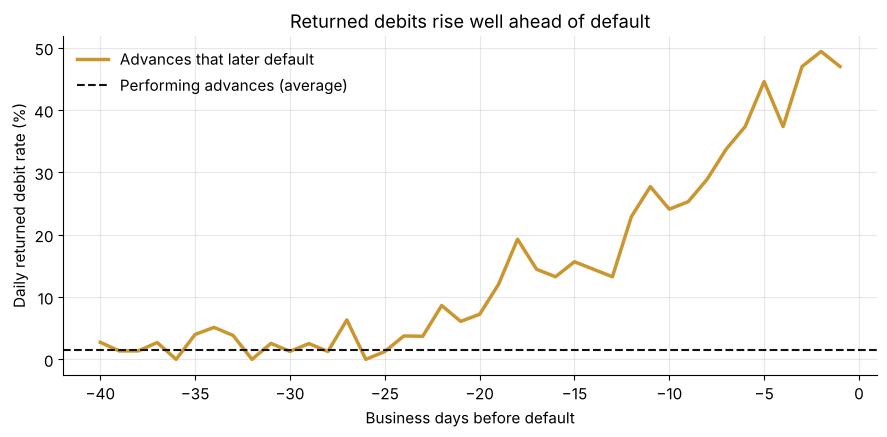

Baseline return rate: 1.51%; 20 days prior: 7.23%; 5 days prior: 44.58%


In [3]:
led = ledger.merge(deals[["advance", "default", "default_day"]], on="advance")
dd = led[led["default"]].copy()
dd["rel"] = dd["day"] - dd["default_day"]
pre = dd[(dd["rel"] >= -40) & (dd["rel"] < 0)].groupby("rel")["returned"].mean()
baseline = led[~led["default"]]["returned"].mean()

fig, ax = plt.subplots()
ax.plot(pre.index, pre.values * 100, color=GOLD, lw=2.5, label="Advances that later default")
ax.axhline(baseline * 100, color=INK, ls="--", lw=1.5, label="Performing advances (average)")
ax.set_xlabel("Business days before default")
ax.set_ylabel("Daily returned debit rate (%)")
ax.set_title("Returned debits rise well ahead of default")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"Baseline return rate: {baseline:.2%}; 20 days prior: {pre.loc[-20]:.2%}; 5 days prior: {pre.loc[-5]:.2%}")

## 3. Collection curves

Cumulative collections as a share of total repayment, plotted against the share of contract term elapsed so that advances of different lengths are comparable.

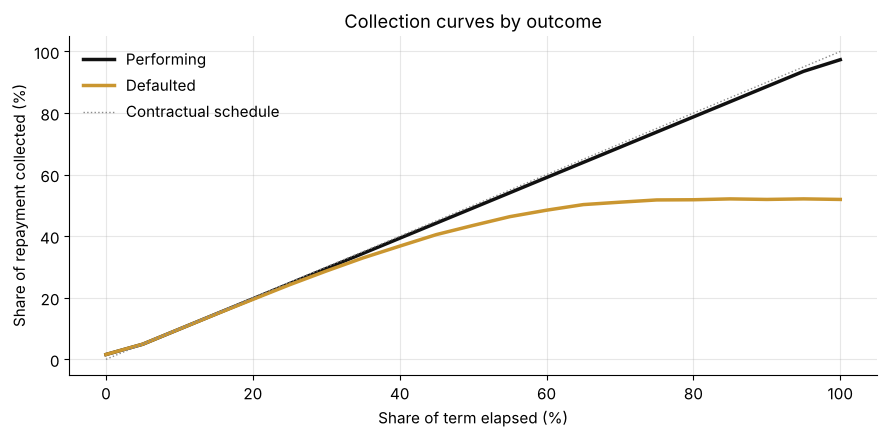

In [4]:
led["cum"] = led.groupby("advance")["collected"].cumsum()
led = led.merge(deals[["advance", "payback", "term"]], on="advance")
led["pct_term"] = (led["day"] + 1) / led["term"]
led["pct_collected"] = led["cum"] / led["payback"]
led["bucket"] = (led["pct_term"] * 20).round() / 20

fig, ax = plt.subplots()
for flag, color, label in [(False, INK, "Performing"), (True, GOLD, "Defaulted")]:
    c = led[led["default"] == flag].groupby("bucket")["pct_collected"].mean()
    ax.plot(c.index * 100, c.values * 100, color=color, lw=2.5, label=label)
ax.plot([0, 100], [0, 100], color=GREY, lw=1, ls=":", label="Contractual schedule")
ax.set_xlabel("Share of term elapsed (%)")
ax.set_ylabel("Share of repayment collected (%)")
ax.set_title("Collection curves by outcome")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Predictive value of trailing return counts

For each advance and each business day before any default, count returned debits over a trailing window and test how well that count predicts a default within the next 30 business days. Area under the ROC curve (AUC) summarizes discrimination across all thresholds.

In [5]:
obs = ledger.merge(deals[["advance", "default", "default_day"]], on="advance")
obs = obs[~obs["default"] | (obs["day"] < obs["default_day"])].copy()
obs["target"] = obs["default"] & (obs["default_day"] - obs["day"] <= 30)

results = []
for w in [5, 10, 15, 20, 30]:
    obs[f"r{w}"] = obs.groupby("advance")["returned"].transform(lambda s: s.rolling(w, min_periods=1).sum())
    results.append((w, roc_auc_score(obs["target"], obs[f"r{w}"])))
auc = pd.DataFrame(results, columns=["window_days", "AUC"]).set_index("window_days").round(3)
auc

,AUC
window_days,
5,0.711
10,0.744
15,0.747
20,0.746
30,0.748


## 5. Watch-list thresholds

Using the 15-day window, a simple rule flags an advance once its trailing returns reach a threshold. Precision is the share of flags that default within 30 days; recall is the share of those defaults flagged in advance.

In [6]:
rows = []
for t in [1, 2, 3, 4, 5]:
    flag = obs["r15"] >= t
    tp = (flag & obs["target"]).sum()
    rows.append((t, tp / max(flag.sum(), 1), tp / obs["target"].sum(), flag.mean()))
pd.DataFrame(rows, columns=["returns_in_15_days", "precision", "recall", "share_of_days_flagged"]).set_index("returns_in_15_days").round(3)

,precision,recall,share_of_days_flagged
returns_in_15_days,,,
1,0.131,0.619,0.211
2,0.470,0.392,0.037
3,0.873,0.271,0.014
4,0.969,0.163,0.008
5,0.986,0.089,0.004


## 6. Observations for underwriting and servicing

- **Returned debits are a leading indicator, not a lagging one.** In this simulation the return rate departs from baseline several weeks before payments stop, which leaves time for merchant contact and workout.
- **Ten business days of history carry the signal.** AUC rises from about 0.71 on a 5-day window to about 0.75 at 10 days and is flat beyond that, so a two-week lookback captures what longer windows capture.
- **Thresholds trade precision against coverage.** A single return in 15 days flags about three in five eventual defaults but is wrong most of the time. Three returns is right nearly nine times in ten while flagging about one advance-day in seventy, which makes it the more practical servicing trigger.
- **Collection curves separate early.** Defaulted advances fall below schedule well before the default date, which supports monitoring collections against the contractual curve rather than against funded amount alone.
- **Daily data is the advantage.** Each of these signals depends on access to daily debit-level activity. Monthly statements would conceal most of the lead time.

*This notebook uses synthetic data for educational and research purposes. It does not describe any actual portfolio.*